In [2]:
import sys
from pathlib import Path

import torch
import matplotlib.pyplot as plt

project_root = Path.cwd().resolve()
if not (project_root / "src/cnn_project").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))

from cnn_project.data import CachedEuroSAT

# Explore all original images, before augmentation and normalization.
dataset = CachedEuroSAT(root=project_root / "data")
class_names = dataset.classes
print(f"Loaded {len(dataset):,} images across {len(class_names)} classes.")


Loaded 27,000 images across 10 classes.


Show an image for each category

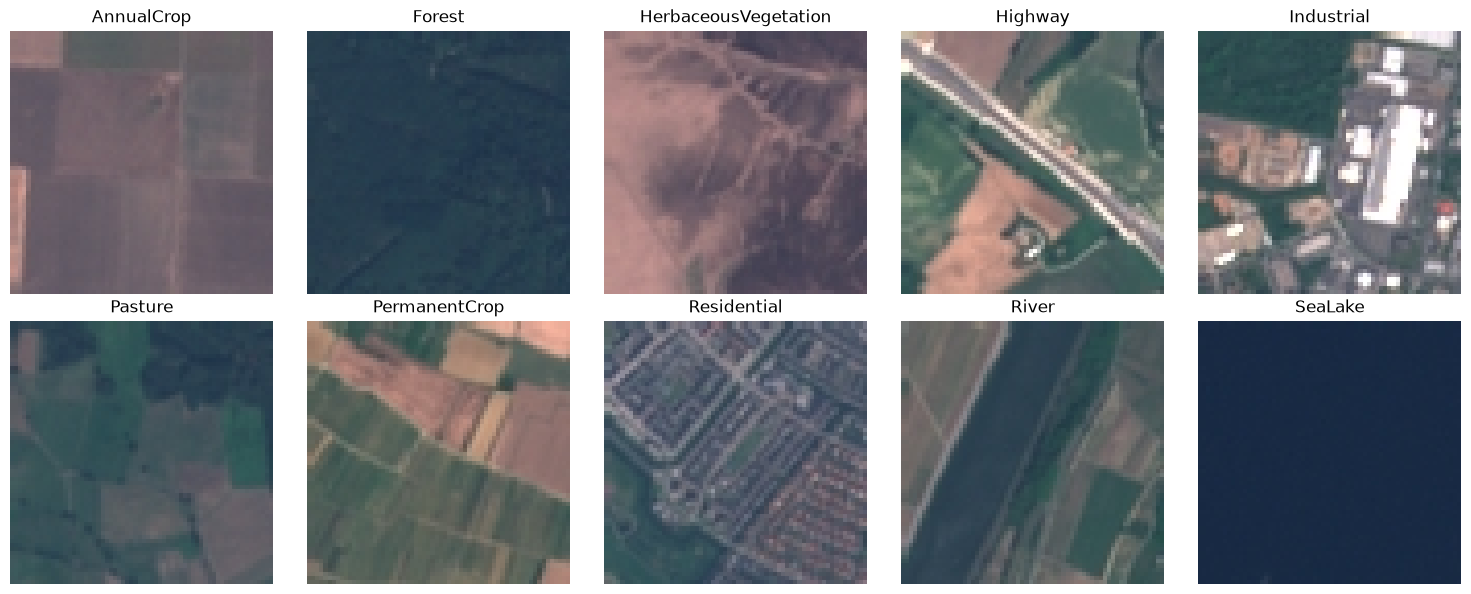

In [3]:
# Show one original image from each category.
first_index = {}
for index, label in enumerate(dataset.labels.tolist()):
    first_index.setdefault(label, index)
    if len(first_index) == len(class_names):
        break

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for label, ax in enumerate(axes.flat):
    image, _ = dataset[first_index[label]]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()


Count the number of images for each category


In [4]:
# Count labels directly without loading or transforming every image.
images_in_category = torch.bincount(
    dataset.labels, minlength=len(class_names)
)

for label, class_name in enumerate(class_names):
    print(
        f"For category {label} - {class_name:<22} "
        f"there are {images_in_category[label].item():,} images"
    )
print(f"Total: {images_in_category.sum().item():,} images")


For category 0 - AnnualCrop             there are 3,000 images
For category 1 - Forest                 there are 3,000 images
For category 2 - HerbaceousVegetation   there are 3,000 images
For category 3 - Highway                there are 2,500 images
For category 4 - Industrial             there are 2,500 images
For category 5 - Pasture                there are 2,000 images
For category 6 - PermanentCrop          there are 2,500 images
For category 7 - Residential            there are 3,000 images
For category 8 - River                  there are 2,500 images
For category 9 - SeaLake                there are 3,000 images
Total: 27,000 images
